# Task 6 — Large-dimensional inverse heat-source reconstruction

**PDE-constrained inverse problem | Numerical analysis | Regularization**

This notebook extends the previous three-Gaussian source model to **25 fixed Gaussian basis functions**. It demonstrates the consequences of sparse temperature observations, ill-conditioning, singular values, and Tikhonov regularization.

We solve $u_t-\alpha\Delta u=f_\theta$ on $\Omega=(0,1)^2$ with zero initial and Dirichlet boundary conditions. The source is $f_\theta=\sum_{r=1}^{25}\theta_r\phi_r$.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from math import ceil
np.set_printoptions(precision=5, suppress=True)
SEED = 20261017

## 1. Finite difference simulation and source basis

On the existing 32×32 grid, each Gaussian basis function is integrated forward using the FTCS stencil

$$U_{ij}^{n+1}=U_{ij}^n+r_x(U_{i+1,j}^n-2U_{ij}^n+U_{i-1,j}^n)+r_y(U_{i,j+1}^n-2U_{ij}^n+U_{i,j-1}^n)+\Delta t\,F_{ij}.$$

We simultaneously propagate 25 independent basis-source responses. The full and sparse matrices are assembled by sampling those temperature fields at prescribed sensors and times. The observations are computed entirely from these simulated fields.

In [ ]:
nx=ny=32; alpha=0.1; T=0.1; nt=46; dt=T/nt
x=np.linspace(0,1,nx+1); y=np.linspace(0,1,ny+1)
X,Y=np.meshgrid(x,y,indexing="ij")
centers=np.array([(a,b) for a in np.linspace(.14,.86,5) for b in np.linspace(.14,.86,5)])
sigma=.085
basis=np.exp(-((X[None]-centers[:,0,None,None])**2+(Y[None]-centers[:,1,None,None])**2)/(2*sigma**2))
p=len(basis)
theta_true=np.array([1.0,0,0.4,0,0.8,0,1.2,0,0.2,0,0.7,0,1.3,0,0.5,0,0.6,0,1.1,0,0.4,0,0.8,0,1.0])
rx=alpha*dt*nx**2; ry=alpha*dt*ny**2
assert rx+ry <= .5
U=np.zeros_like(basis); steps=[12,23,46]; snapshots={}
for n in range(1,nt+1):
    V=np.zeros_like(U)
    V[:,1:-1,1:-1]=(U[:,1:-1,1:-1]+rx*(U[:,2:,1:-1]-2*U[:,1:-1,1:-1]+U[:,:-2,1:-1])+ry*(U[:,1:-1,2:]-2*U[:,1:-1,1:-1]+U[:,1:-1,:-2])+dt*basis[:,1:-1,1:-1])
    U=V
    if n in steps:snapshots[n]=U.copy()
print('Stability r_x+r_y:',rx+ry)

Stability r_x+r_y: 0.44521739130434784


## 2. Observation matrices

Each column of $A$ is the measured response to one unit-amplitude Gaussian basis source. We compare **48 observations (16 sensors × 3 times)** with **18 observations (6 sensors × 3 times)**. In the sparse case $A_{18}\in\mathbb R^{18\times25}$, so the matrix cannot have full column rank.

In [ ]:
sensor_values=np.array([5,12,20,27])
sensors=np.array([(i,j) for i in sensor_values for j in sensor_values])
sparse_sensors=sensors[np.array([0,2,5,10,13,15])]
def response(sensors):
    return np.vstack([snapshots[t][:,sensors[:,0],sensors[:,1]].T for t in steps])
A=response(sensors); A_sparse=response(sparse_sensors)
print('Shapes, ranks:',A.shape,np.linalg.matrix_rank(A),A_sparse.shape,np.linalg.matrix_rank(A_sparse))
print('Condition of full matrix:',np.linalg.cond(A))
print('Nonzero singular-value ratio, sparse:',np.linalg.svd(A_sparse,compute_uv=False)[0]/np.linalg.svd(A_sparse,compute_uv=False)[-1])

Shapes, ranks: (48, 25) 25 (18, 25) 18
Condition of full matrix: 1025.2027946540254
Nonzero singular-value ratio, sparse: 3029.0180257259694


## 3. Simulated observations and inverse regularization

We define $d=A\theta_\mathrm{true}+\varepsilon$, with Gaussian noise of standard deviation $0.03\max |A\theta_\mathrm{true}|$. Reconstruct by minimizing

$$J_\lambda(\theta)=\frac{1}{2m}\|A\theta-d\|_2^2+\frac{\lambda}{2}\|\theta\|_2^2.$$

The normal equations are $(A^TA+m\lambda I)\hat\theta=A^Td$. Set $\lambda=10^{-3}s_1^2/m_\mathrm{full}$ as a **fixed heuristic**, not a theoretically optimized parameter. This common absolute penalty is used in both sensor scenarios for comparability.

In [ ]:
rng1=np.random.default_rng(1)
def observe(M,seed=1):
    clean=M@theta_true
    sd=.03*np.max(np.abs(clean))
    return clean,clean+np.random.default_rng(seed).normal(0,sd,len(clean))
d_clean,d=observe(A); d_small_clean,d_small=observe(A_sparse)
scale=np.linalg.svd(A,compute_uv=False)[0]**2/len(d)
lam=1e-3*scale
def ridge(M,obs,lam):
    return np.linalg.solve(M.T@M+len(obs)*lam*np.eye(M.shape[1]),M.T@obs)
def source_error(z):
    f_est=np.einsum('p,pij->ij',z,basis)
    f_true=np.einsum('p,pij->ij',theta_true,basis)
    return np.linalg.norm(f_est-f_true)/np.linalg.norm(f_true)
full_ls=np.linalg.lstsq(A,d,rcond=None)[0]
small_ls=np.linalg.lstsq(A_sparse,d_small,rcond=None)[0]
full_ridge=ridge(A,d,lam); small_ridge=ridge(A_sparse,d_small,lam)
for label,z in [('full LS',full_ls),('full ridge',full_ridge),('sparse minimum norm LS',small_ls),('sparse ridge',small_ridge)]:
    print(label,'source relative error:',source_error(z))

full LS source relative error: 3.85375366061156
full ridge source relative error: 0.2960095934899062
sparse minimum norm LS source relative error: 4.912280664266633
sparse ridge source relative error: 0.43930969461640956


## 4. Singular values, source fields and regularization trade-off

The sparse configuration admits nonzero coefficient vectors $z$ satisfying $A_\mathrm{sparse}z=0$: thus multiple sources are observationally indistinguishable in the noiseless discrete model. Even the full configuration may exhibit small singular values and amplify noise.

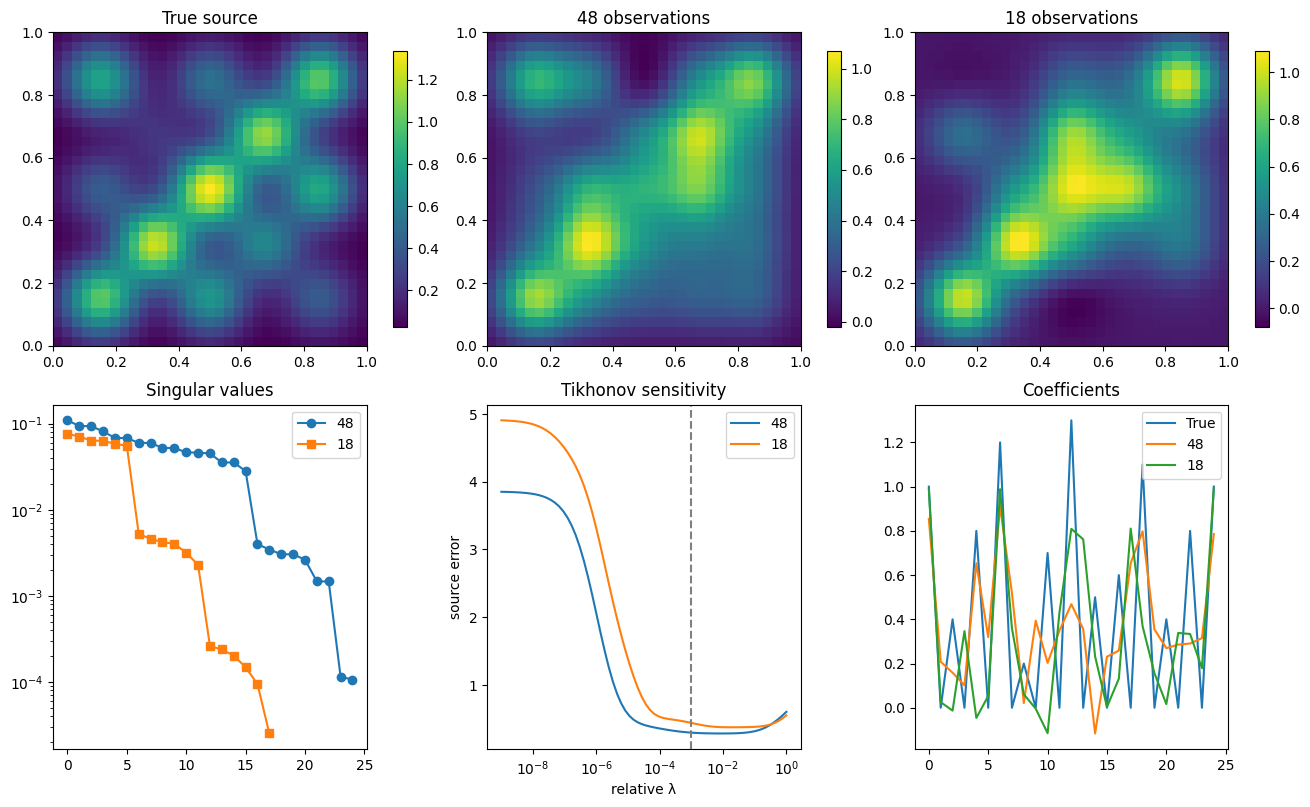

In [ ]:
fig,axs=plt.subplots(2,3,figsize=(13,8),constrained_layout=True)
f_true=np.einsum('p,pij->ij',theta_true,basis)
for ax,source,label in zip(axs[0],[f_true,np.einsum('p,pij->ij',full_ridge,basis),np.einsum('p,pij->ij',small_ridge,basis)],['True source','48 observations','18 observations']):
    im=ax.imshow(source.T,origin='lower',extent=[0,1,0,1]); ax.set_title(label);fig.colorbar(im,ax=ax,shrink=.8)
s1=np.linalg.svd(A,compute_uv=False); s2=np.linalg.svd(A_sparse,compute_uv=False)
axs[1,0].semilogy(s1,'o-',label='48');axs[1,0].semilogy(s2,'s-',label='18');axs[1,0].set_title('Singular values');axs[1,0].legend()
rel_grid=np.logspace(-9,0,70)
errs1=[source_error(ridge(A,d,g*scale)) for g in rel_grid]
errs2=[source_error(ridge(A_sparse,d_small,g*scale)) for g in rel_grid]
axs[1,1].semilogx(rel_grid,errs1,label='48');axs[1,1].semilogx(rel_grid,errs2,label='18');axs[1,1].axvline(1e-3,color='gray',ls='--');axs[1,1].set(title='Tikhonov sensitivity',xlabel='relative λ',ylabel='source error');axs[1,1].legend()
axs[1,2].plot(theta_true,label='True');axs[1,2].plot(full_ridge,label='48');axs[1,2].plot(small_ridge,label='18');axs[1,2].set_title('Coefficients');axs[1,2].legend()
plt.show()

## 5. Repeated-noise evaluation

Repeat the noisy experiment 100 times under each sensor configuration. Compare unregularized minimum-norm least squares with fixed-parameter ridge, using relative spatial-source error as the metric. This tests whether conclusions persist beyond a single noise realization.

In [ ]:
rng=np.random.default_rng(SEED)
for label,M in [('48 observations',A),('18 observations',A_sparse)]:
    clean=M@theta_true; sd=.03*np.max(np.abs(clean)); e_ls=[];e_ridge=[]
    for _ in range(100):
        obs=clean+rng.normal(0,sd,len(clean))
        e_ls.append(source_error(np.linalg.lstsq(M,obs,rcond=None)[0]))
        e_ridge.append(source_error(ridge(M,obs,lam)))
    print(label,'LS mean ± SD:',np.mean(e_ls),np.std(e_ls),'ridge mean ± SD:',np.mean(e_ridge),np.std(e_ridge))

48 observations LS mean ± SD: 4.3533887010320775 2.373469902212316 ridge mean ± SD: 0.31229044478852014 0.039081904886011515
18 observations LS mean ± SD: 21.684247366195823 11.310613027268452 ridge mean ± SD: 0.4817263195569019 0.06603500377437906


In [13]:

# Save Task 6 numerical results

import numpy as np

np.savez_compressed(
    "phase6_large_inverse_data.npz",
    A=A,
    A_sparse=A_sparse,
    theta_true=theta_true,
    basis=basis,
    full_observations=d,
    sparse_observations=d_small,
)

print("Task 6 numerical results saved successfully!")


Task 6 numerical results saved successfully!


## 6. Conclusions and limitations

1. A larger source basis makes the inverse task harder even though the forward PDE remains linear.
2. With fewer measurements than unknowns, unique coefficient recovery is mathematically impossible without further structural assumptions; regularization selects one solution, but cannot create missing information.
3. Singular values diagnose sensitivity, while regularization trades variance against bias.
4. Our true source lies in the chosen basis by construction. A later experiment should introduce model mismatch, off-grid observations, and coarser-vs-finer PDE solvers to test discretization effects.
5. Basis centers and widths are known; only amplitudes are estimated.

**Next research direction:** Discretization sensitivity and model mismatch, or adjoint-state gradients for larger PDE-constrained inverse problems.